In [3]:
import sys
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Python Version:", sys.version)
print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("Scikit-learn Version:", sklearn.__version__)

print("\nGPU Available:",
      tf.config.list_physical_devices('GPU'))

print("\n All libraries imported successfully!")

Python Version: 3.14.10 | packaged by Anaconda, Inc. | (main, Oct 27 2026, 01:09:10) [MSC v.1942 64 bit (AMD64)]
TensorFlow Version: 2.22.0-rc0
NumPy Version: 2.5.4
Pandas Version: 3.1.1
Scikit-learn Version: 1.9.1

GPU Available: []

 All libraries imported successfully!


In [4]:
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\harin\OneDrive\Desktop\5th Sem\Neural Network"
)

print("Dataset folder exists:", DATA_DIR.exists())

if DATA_DIR.exists():

    classes = [
        folder for folder in DATA_DIR.iterdir()
        if folder.is_dir()
    ]

    print("Number of classes:", len(classes))

    for folder in sorted(classes):
        print(folder.name)

Dataset folder exists: True
Number of classes: 1
Dataset-Bacteria


In [5]:
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\harin\OneDrive\Desktop\5th Sem\Neural Network"
)

print("Dataset location:", DATA_DIR)
print("Folder exists:", DATA_DIR.exists())

Dataset location: C:\Users\harin\OneDrive\Desktop\5th Sem\Neural Network
Folder exists: True


In [6]:
classes = sorted([
    folder.name
    for folder in DATA_DIR.iterdir()
    if folder.is_dir()
])

print("Total microbial classes:", len(classes))

print("\nAvailable classes:")

for i, name in enumerate(classes, 1):
    print(i, "-", name)

Total microbial classes: 1

Available classes:
1 - Dataset-Bacteria


In [7]:
from pathlib import Path

INNER_DIR = DATA_DIR / "Dataset-Bacteria"

print("Inner folder exists:", INNER_DIR.exists())

if INNER_DIR.exists():

    print("\nContents of Dataset-Bacteria:")

    for item in sorted(INNER_DIR.iterdir()):
        print(item.name)

Inner folder exists: True

Contents of Dataset-Bacteria:
Dataset-Bacteria


In [8]:
DATA_DIR = DATA_DIR / "Dataset-Bacteria"

classes = sorted([
    folder.name
    for folder in DATA_DIR.iterdir()
    if folder.is_dir()
])

print("Total microbial classes:", len(classes))

for i, name in enumerate(classes, 1):
    print(i, "-", name)

Total microbial classes: 1
1 - Dataset-Bacteria


In [9]:
INNER_DIR = DATA_DIR / "Dataset-Bacteria"

SECOND_INNER_DIR = INNER_DIR / "Dataset-Bacteria"

print("Second inner folder exists:",
      SECOND_INNER_DIR.exists())

if SECOND_INNER_DIR.exists():

    print("\nContents of second inner folder:")

    for item in sorted(SECOND_INNER_DIR.iterdir()):
        print(item.name)

Second inner folder exists: False


In [10]:
from pathlib import Path

print("Searching inside:", DATA_DIR)

for item in DATA_DIR.rglob("*"):
    if item.is_dir():
        image_count = sum(
            1 for f in item.iterdir()
            if f.is_file() and
            f.suffix.lower() in [
                ".jpg", ".jpeg", ".png",
                ".bmp", ".tif", ".tiff"
            ]
        )

        if image_count > 0:
            print(item, ":", image_count, "images")

Searching inside: C:\Users\harin\OneDrive\Desktop\5th Sem\Neural Network\Dataset-Bacteria
C:\Users\harin\OneDrive\Desktop\5th Sem\Neural Network\Dataset-Bacteria\Dataset-Bacteria\Acinetobacter baumannii : 60 images
C:\Users\harin\OneDrive\Desktop\5th Sem\Neural Network\Dataset-Bacteria\Dataset-Bacteria\Actinomyces israelii : 67 images
C:\Users\harin\OneDrive\Desktop\5th Sem\Neural Network\Dataset-Bacteria\Dataset-Bacteria\Bacteroides fragilis : 65 images
C:\Users\harin\OneDrive\Desktop\5th Sem\Neural Network\Dataset-Bacteria\Dataset-Bacteria\Bifidobacterium spp : 64 images
C:\Users\harin\OneDrive\Desktop\5th Sem\Neural Network\Dataset-Bacteria\Dataset-Bacteria\Candida albicans : 62 images
C:\Users\harin\OneDrive\Desktop\5th Sem\Neural Network\Dataset-Bacteria\Dataset-Bacteria\Clostridium perfringens : 62 images
C:\Users\harin\OneDrive\Desktop\5th Sem\Neural Network\Dataset-Bacteria\Dataset-Bacteria\Enterococcus faecalis : 60 images
C:\Users\harin\OneDrive\Desktop\5th Sem\Neural Network

In [11]:
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\harin\OneDrive\Desktop\5th Sem\Neural Network\Dataset-Bacteria\Dataset-Bacteria"
)

print("Dataset folder exists:", DATA_DIR.exists())

classes = sorted([
    folder.name
    for folder in DATA_DIR.iterdir()
    if folder.is_dir()
])

print("Total microbial classes:", len(classes))

for i, name in enumerate(classes, start=1):
    print(f"{i}. {name}")

Dataset folder exists: True
Total microbial classes: 33
1. Acinetobacter baumannii
2. Actinomyces israelii
3. Bacteroides fragilis
4. Bifidobacterium spp
5. Candida albicans
6. Clostridium perfringens
7. Enterococcus faecalis
8. Enterococcus faecium
9. Escherichia coli
10. Fusobacterium
11. Lactobacillus casei
12. Lactobacillus crispatus
13. Lactobacillus delbrueckii
14. Lactobacillus gasseri
15. Lactobacillus jensenii
16. Lactobacillus johnsonii
17. Lactobacillus paracasei
18. Lactobacillus plantarum
19. Lactobacillus reuteri
20. Lactobacillus rhamnosus
21. Lactobacillus salivarius
22. Listeria monocytogenes
23. Micrococcus spp
24. Neisseria gonorrhoeae
25. Porphyromonas gingivalis
26. Propionibacterium acnes
27. Proteus
28. Pseudomonas aeruginosa
29. Staphylococcus aureus
30. Staphylococcus epidermidis
31. Staphylococcus saprophyticus
32. Streptococcus agalactiae
33. Veillonella


In [12]:
import pandas as pd

image_extensions = [".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"]

class_data = []

for folder in sorted(DATA_DIR.iterdir()):
    if folder.is_dir():
        images = [
            file for file in folder.iterdir()
            if file.is_file() and file.suffix.lower() in image_extensions
        ]

        class_data.append({
            "Microbial Class": folder.name,
            "Image Count": len(images)
        })

df = pd.DataFrame(class_data)

print("Total images:", df["Image Count"].sum())
display(df)

Total images: 2034


,Microbial Class,Image Count
0,Acinetobacter baumannii,60
1,Actinomyces israelii,67
2,Bacteroides fragilis,65
3,Bifidobacterium spp,64
4,Candida albicans,62
5,Clostridium perfringens,62
6,Enterococcus faecalis,60
7,Enterococcus faecium,58
8,Escherichia coli,59
9,Fusobacterium,62


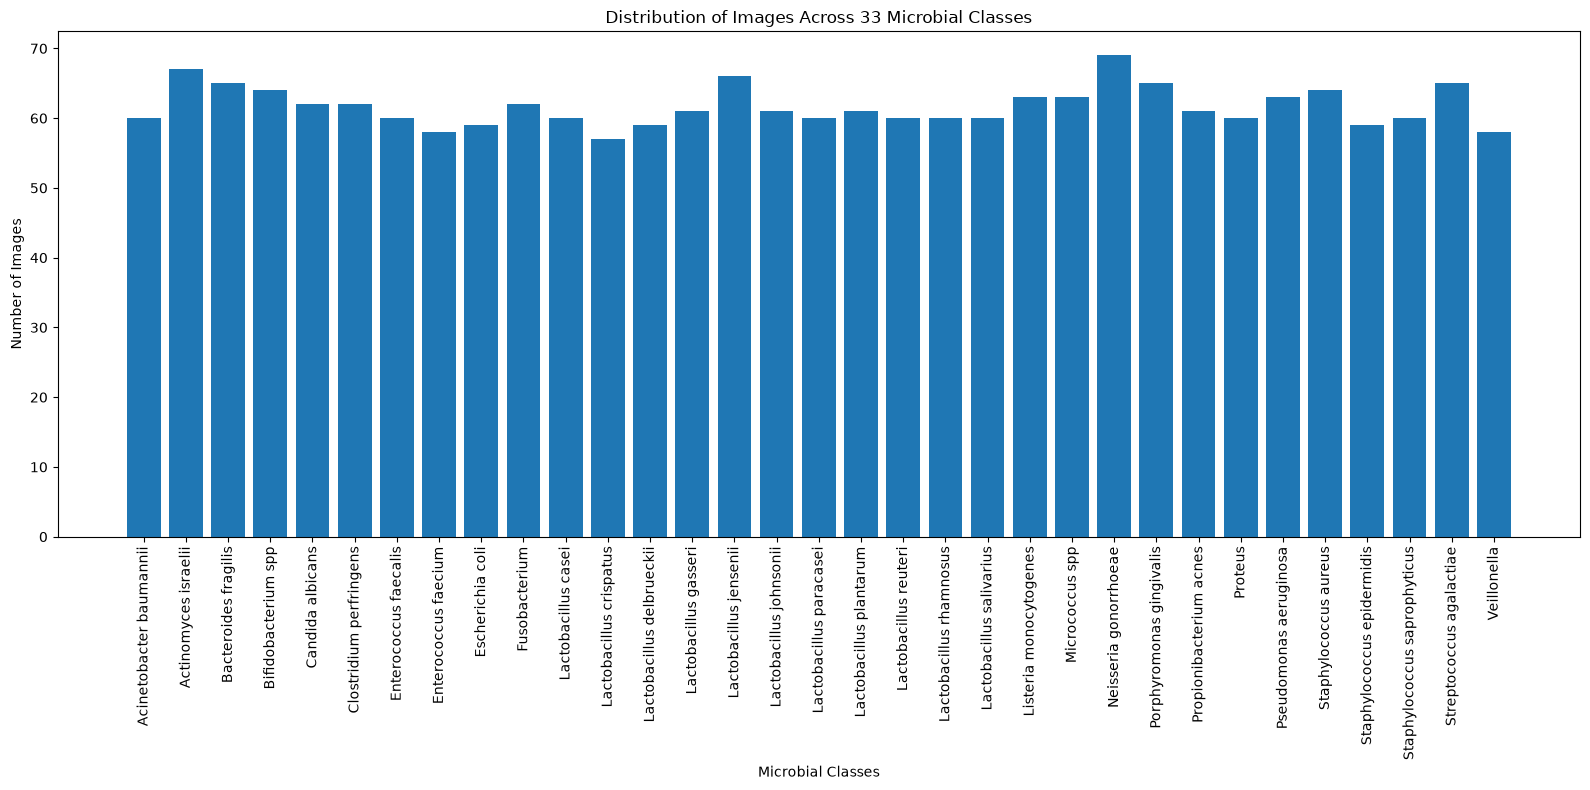

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 8))

plt.bar(
    df["Microbial Class"],
    df["Image Count"]
)

plt.xlabel("Microbial Classes")
plt.ylabel("Number of Images")
plt.title("Distribution of Images Across 33 Microbial Classes")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

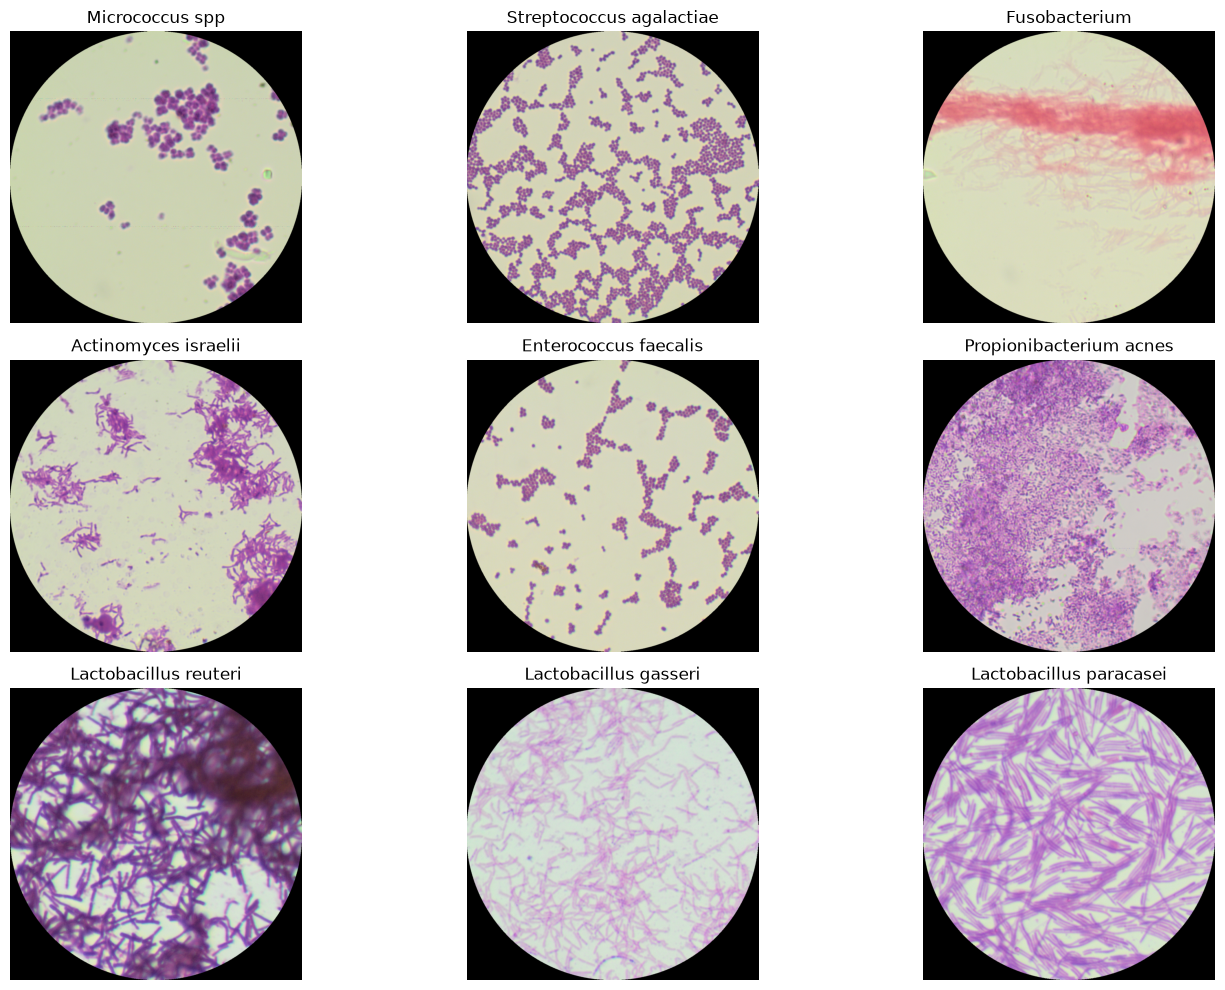

In [14]:
import matplotlib.pyplot as plt
from PIL import Image
import random

plt.figure(figsize=(15, 10))

selected_classes = random.sample(classes, 9)

for i, class_name in enumerate(selected_classes):
    folder = DATA_DIR / class_name

    image_files = [
        f for f in folder.iterdir()
        if f.suffix.lower() in image_extensions
    ]

    image_path = random.choice(image_files)

    img = Image.open(image_path).convert("RGB")

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
from PIL import Image
from collections import Counter

image_sizes = Counter()
corrupted_images = []
total_images = 0

for folder in DATA_DIR.iterdir():
    if folder.is_dir():
        for file in folder.iterdir():
            if file.suffix.lower() in image_extensions:
                total_images += 1

                try:
                    with Image.open(file) as img:
                        image_sizes[img.size] += 1
                        img.verify()

                except Exception:
                    corrupted_images.append(str(file))

print("Total images:", total_images)
print("\nMost common image dimensions:")

for size, count in image_sizes.most_common(10):
    print(f"{size}: {count} images")

print("\nCorrupted images:", len(corrupted_images))

Total images: 2034

Most common image dimensions:
(1225, 1225): 571 images
(1112, 1112): 63 images
(1081, 1081): 57 images
(1116, 1116): 54 images
(1090, 1090): 51 images
(1103, 1103): 51 images
(1042, 1042): 46 images
(1064, 1064): 43 images
(1073, 1073): 42 images
(1051, 1051): 42 images

Corrupted images: 0


In [16]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Collect image paths and their class labels
image_data = []

for folder in DATA_DIR.iterdir():
    if folder.is_dir():
        for file in folder.iterdir():
            if file.suffix.lower() in image_extensions:
                image_data.append({
                    "filepath": str(file),
                    "label": folder.name
                })

data = pd.DataFrame(image_data)

# First split: 70% training, 30% temporary
train_data, temp_data = train_test_split(
    data,
    test_size=0.30,
    stratify=data["label"],
    random_state=42
)

# Second split: divide temporary data equally
val_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    stratify=temp_data["label"],
    random_state=42
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))

print("\nClasses in each set:")
print("Training:", train_data["label"].nunique())
print("Validation:", val_data["label"].nunique())
print("Testing:", test_data["label"].nunique())

Training images: 1423
Validation images: 305
Testing images: 306

Classes in each set:
Training: 33
Validation: 33
Testing: 33


In [17]:
import tensorflow as tf
import numpy as np

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Assign a numerical label to each microbial class
class_names = sorted(data["label"].unique())

class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

print("Number of classes:", len(class_names))
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Number of classes: 33
Image size: (224, 224)
Batch size: 32


In [18]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel value range:",
      float(tf.reduce_min(images)),
      "to",
      float(tf.reduce_max(images)))

NameError: name 'train_ds' is not defined

In [19]:
train_ds = create_dataset(train_data, shuffle=True)
val_ds = create_dataset(val_data)
test_ds = create_dataset(test_data)

print("TensorFlow datasets created successfully!")


NameError: name 'create_dataset' is not defined

In [20]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(filepath, label):

    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)

    image = tf.cast(image, tf.float32) / 255.0

    return image, label


def create_dataset(frame, shuffle=False):

    paths = frame["filepath"].values

    labels = frame["label"].map(class_to_index).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(frame),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    return dataset.prefetch(tf.data.AUTOTUNE)


print("Image loading functions defined successfully!")

Image loading functions defined successfully!


In [21]:
train_ds = create_dataset(train_data, shuffle=True)
val_ds = create_dataset(val_data)
test_ds = create_dataset(test_data)

print("All three datasets created successfully!")

All three datasets created successfully!


In [22]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Minimum pixel value:", float(tf.reduce_min(images)))
print("Maximum pixel value:", float(tf.reduce_max(images)))

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [23]:
from tensorflow.keras import layers, models

cnn_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Fourth convolution block
    layers.Conv2D(256, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(33, activation="softmax")
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 24, 24, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 12, 12, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 36864)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │       9,437,440 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 33)                  │           8,481 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 9,834,337 (37.52 MB)

 Trainable params: 9,834,337 (37.52 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [25]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "best_cnn_model.keras",
    monitor="val_loss",
    save_best_only=True
)

history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/20


C:\Users\harin\anaconda3\envs\Microbiology_AI\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


45/45 ━━━━━━━━━━━━━━━━━━━━ 53s 1s/step - accuracy: 0.0267 - loss: 3.5828 - val_accuracy: 0.0328 - val_loss: 3.4965
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 76s 1s/step - accuracy: 0.0260 - loss: 3.4966 - val_accuracy: 0.0328 - val_loss: 3.4964
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.0309 - loss: 3.4967 - val_accuracy: 0.0328 - val_loss: 3.4964
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.0394 - loss: 3.4966 - val_accuracy: 0.0328 - val_loss: 3.4963
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.0330 - loss: 3.4967 - val_accuracy: 0.0328 - val_loss: 3.4963
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.0316 - loss: 3.4965 - val_accuracy: 0.0328 - val_loss: 3.4962
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 47s 1s/step - accuracy: 0.0302 - loss: 3.4964 - val_accuracy: 0.0328 - val_loss: 3.4962
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 79s 974ms/step - accuracy: 0.0365 - loss: 3.4964 - val_accuracy: 0.0328 - val_loss: 3.4961


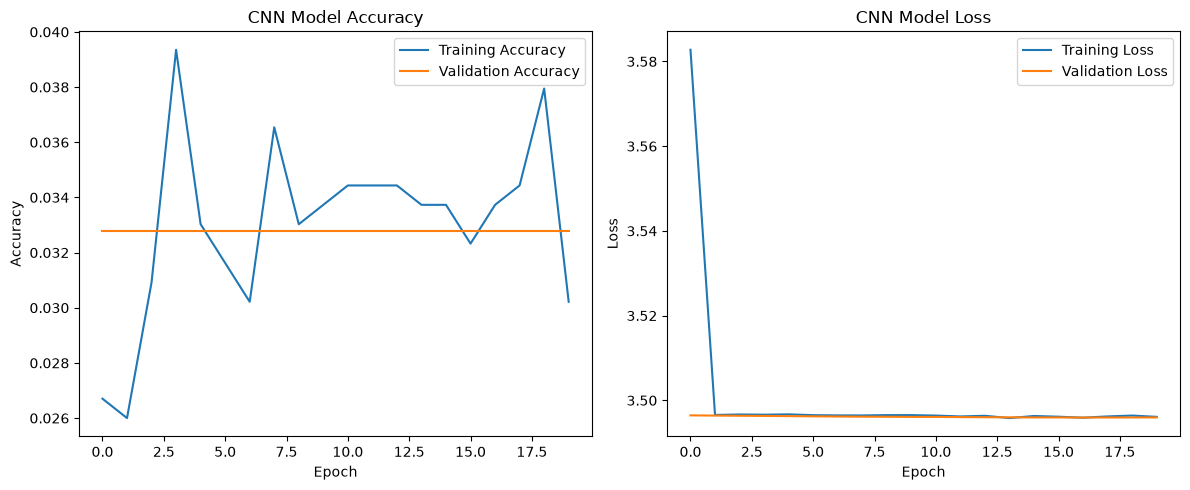

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Check label distribution
print("Training label distribution:")
print(train_data["label"].value_counts().sort_index())

# Check unique numerical labels
all_labels = np.concatenate([
    labels.numpy()
    for images, labels in train_ds
])

print("\nUnique numerical labels:", np.unique(all_labels))
print("Number of unique labels:", len(np.unique(all_labels)))

# Check image variation
images, labels = next(iter(train_ds))

print("\nImage mean:", float(tf.reduce_mean(images)))
print("Image standard deviation:", float(tf.math.reduce_std(images)))

Training label distribution:
label
Acinetobacter baumannii         42
Actinomyces israelii            47
Bacteroides fragilis            45
Bifidobacterium spp             45
Candida albicans                43
Clostridium perfringens         43
Enterococcus faecalis           42
Enterococcus faecium            41
Escherichia coli                41
Fusobacterium                   43
Lactobacillus casei             42
Lactobacillus crispatus         40
Lactobacillus delbrueckii       41
Lactobacillus gasseri           43
Lactobacillus jensenii          46
Lactobacillus johnsonii         43
Lactobacillus paracasei         42
Lactobacillus plantarum         43
Lactobacillus reuteri           42
Lactobacillus rhamnosus         42
Lactobacillus salivarius        42
Listeria monocytogenes          44
Micrococcus spp                 44
Neisseria gonorrhoeae           48
Porphyromonas gingivalis        45
Propionibacterium acnes         43
Proteus                         42
Pseudomonas aerugino

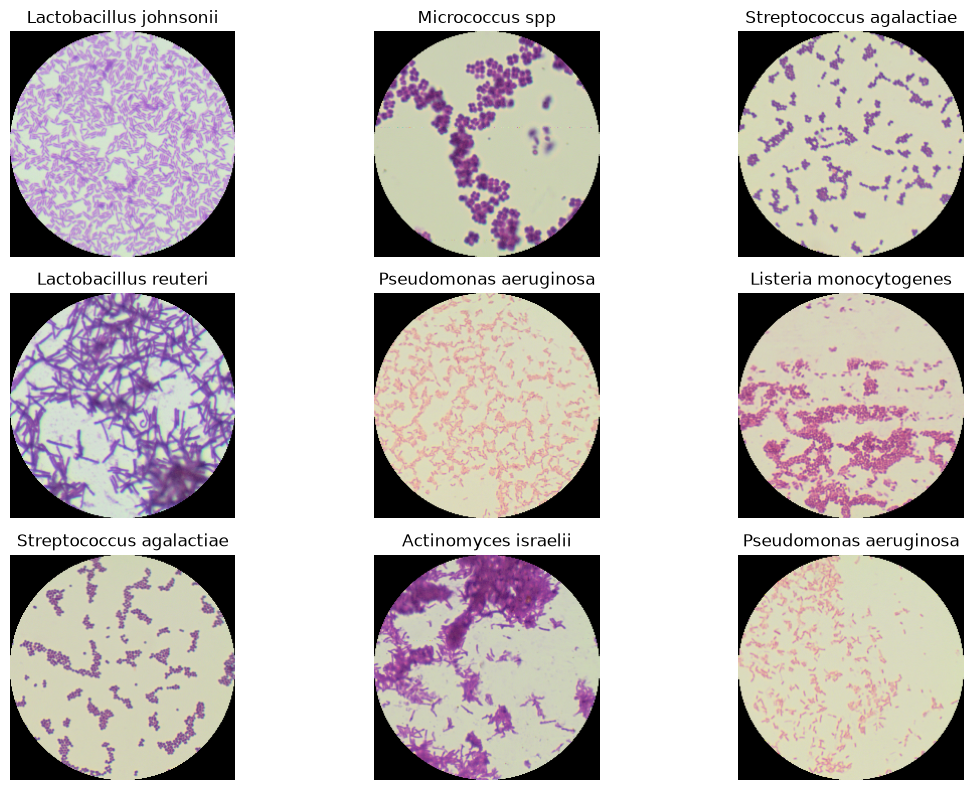

In [28]:
plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i].numpy())

    actual_label = class_names[int(labels[i].numpy())]

    plt.title(actual_label)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [29]:
predictions = cnn_model.predict(images[:9])

for i in range(9):
    predicted_index = np.argmax(predictions[i])

    print(
        "Actual:", class_names[int(labels[i].numpy())],
        "| Predicted:", class_names[predicted_index],
        "| Confidence:", round(float(np.max(predictions[i])) * 100, 2), "%"
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step
Actual: Lactobacillus johnsonii | Predicted: Neisseria gonorrhoeae | Confidence: 3.23 %
Actual: Micrococcus spp | Predicted: Neisseria gonorrhoeae | Confidence: 3.23 %
Actual: Streptococcus agalactiae | Predicted: Neisseria gonorrhoeae | Confidence: 3.23 %
Actual: Lactobacillus reuteri | Predicted: Neisseria gonorrhoeae | Confidence: 3.23 %
Actual: Pseudomonas aeruginosa | Predicted: Neisseria gonorrhoeae | Confidence: 3.23 %
Actual: Listeria monocytogenes | Predicted: Neisseria gonorrhoeae | Confidence: 3.23 %
Actual: Streptococcus agalactiae | Predicted: Neisseria gonorrhoeae | Confidence: 3.23 %
Actual: Actinomyces israelii | Predicted: Neisseria gonorrhoeae | Confidence: 3.23 %
Actual: Pseudomonas aeruginosa | Predicted: Neisseria gonorrhoeae | Confidence: 3.23 %


In [30]:
# Examine predictions for one batch
predictions = cnn_model.predict(images, verbose=0)

print("Prediction probability range:")
print("Minimum:", np.min(predictions))
print("Maximum:", np.max(predictions))

print("\nMean prediction confidence:",
      np.mean(np.max(predictions, axis=1)))

print("\nNumber of unique predicted classes:",
      len(np.unique(np.argmax(predictions, axis=1))))

print("\nFirst prediction probabilities:")
print(np.round(predictions[0], 5))

Prediction probability range:
Minimum: 0.029046217
Maximum: 0.032341804

Mean prediction confidence: 0.032341804

Number of unique predicted classes: 1

First prediction probabilities:
[0.02987 0.03188 0.03144 0.03099 0.03035 0.03033 0.02989 0.02918 0.02931
 0.03018 0.02991 0.02905 0.02906 0.03036 0.03153 0.03031 0.0299  0.03011
 0.03    0.02966 0.02969 0.03069 0.03087 0.03234 0.03122 0.03035 0.02973
 0.03041 0.03116 0.02935 0.02998 0.0316  0.02929]


In [31]:
final_weights = cnn_model.layers[-1].get_weights()

print("Final layer weight shape:", final_weights[0].shape)
print("Weight standard deviation:", np.std(final_weights[0]))
print("Bias standard deviation:", np.std(final_weights[1]))

Final layer weight shape: (256, 33)
Weight standard deviation: 0.082962334
Bias standard deviation: 0.021092528


In [32]:

# STEP 1: Build and train an improved CNN

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Confirm the number of classes
NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)

# Smaller CNN with Global Average Pooling
improved_cnn = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

# Compile
improved_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

improved_cnn.summary()

# Training callbacks
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "best_improved_cnn.keras",
    monitor="val_loss",
    save_best_only=True
)

# Train
history_improved = improved_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[early_stop, checkpoint]
)

print("\nTraining completed!")


Number of classes: 33


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)                    │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 224, 224, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 112, 112, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 56, 56, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 28, 28, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 28, 28, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 33)                  │           4,257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 427,489 (1.63 MB)

 Trainable params: 426,529 (1.63 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 65s 1s/step - accuracy: 0.3169 - loss: 2.2705 - val_accuracy: 0.0295 - val_loss: 3.5893
Epoch 2/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.4905 - loss: 1.5032 - val_accuracy: 0.0295 - val_loss: 5.7023
Epoch 3/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.6058 - loss: 1.1811 - val_accuracy: 0.0525 - val_loss: 6.7105
Epoch 4/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.6486 - loss: 1.0324 - val_accuracy: 0.0787 - val_loss: 8.7281

Training completed!


In [33]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report

# Evaluate training and validation performance
train_loss, train_acc = improved_cnn.evaluate(train_ds, verbose=0)
val_loss, val_acc = improved_cnn.evaluate(val_ds, verbose=0)

print("TRAINING PERFORMANCE")
print("Accuracy:", round(train_acc * 100, 2), "%")
print("Loss:", round(train_loss, 4))

print("\nVALIDATION PERFORMANCE")
print("Accuracy:", round(val_acc * 100, 2), "%")
print("Loss:", round(val_loss, 4))

# Get validation predictions
y_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

y_prob = improved_cnn.predict(val_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Class-wise performance
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# Check prediction distribution
print("Number of predicted classes:",
      len(np.unique(y_pred)))

print("Average prediction confidence:",
      round(float(np.mean(np.max(y_prob, axis=1))) * 100, 2), "%")


TRAINING PERFORMANCE
Accuracy: 3.02 %
Loss: 3.5979

VALIDATION PERFORMANCE
Accuracy: 2.95 %
Loss: 3.5893

CLASSIFICATION REPORT
                              precision    recall  f1-score   support

     Acinetobacter baumannii       0.00      0.00      0.00         9
        Actinomyces israelii       0.00      0.00      0.00        10
        Bacteroides fragilis       0.00      0.00      0.00        10
         Bifidobacterium spp       0.00      0.00      0.00         9
            Candida albicans       0.00      0.00      0.00         9
     Clostridium perfringens       0.00      0.00      0.00        10
       Enterococcus faecalis       0.00      0.00      0.00         9
        Enterococcus faecium       0.00      0.00      0.00         9
            Escherichia coli       0.00      0.00      0.00         9
               Fusobacterium       0.00      0.00      0.00         9
         Lactobacillus casei       0.00      0.00      0.00         9
     Lactobacillus crispatus   

In [34]:
import numpy as np

# Take one batch from the training dataset
images, labels = next(iter(train_ds))

# Compare predictions in training mode and evaluation mode
pred_training_mode = improved_cnn(images, training=True).numpy()
pred_evaluation_mode = improved_cnn(images, training=False).numpy()

print("TRUE LABELS (first 10):")
print(labels.numpy()[:10])

print("\nPREDICTIONS IN TRAINING MODE:")
print(np.argmax(pred_training_mode, axis=1)[:10])
print("Unique predicted classes:",
      len(np.unique(np.argmax(pred_training_mode, axis=1))))

print("\nPREDICTIONS IN EVALUATION MODE:")
print(np.argmax(pred_evaluation_mode, axis=1)[:10])
print("Unique predicted classes:",
      len(np.unique(np.argmax(pred_evaluation_mode, axis=1))))

print("\nAVERAGE CONFIDENCE")
print("Training mode:",
      round(float(np.mean(np.max(pred_training_mode, axis=1))) * 100, 2), "%")
print("Evaluation mode:",
      round(float(np.mean(np.max(pred_evaluation_mode, axis=1))) * 100, 2), "%")

print("\nBATCH NORMALIZATION STATISTICS")
for layer in improved_cnn.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        print(
            layer.name,
            "moving variance range:",
            float(np.min(layer.moving_variance.numpy())),
            "to",
            float(np.max(layer.moving_variance.numpy()))
        )

TRUE LABELS (first 10):
[29  9  2  7 16 31 30  3 24  7]

PREDICTIONS IN TRAINING MODE:
[28 26 26 22 13 28 30  3 21 28]
Unique predicted classes: 21

PREDICTIONS IN EVALUATION MODE:
[13 13 13 13 13 13 13 13 13 13]
Unique predicted classes: 1

AVERAGE CONFIDENCE
Training mode: 35.82 %
Evaluation mode: 14.17 %

BATCH NORMALIZATION STATISTICS
batch_normalization moving variance range: 0.6298239231109619 to 0.6604824066162109
batch_normalization_1 moving variance range: 0.6383676528930664 to 1.1210345029830933
batch_normalization_2 moving variance range: 0.6708959937095642 to 2.4912283420562744
batch_normalization_3 moving variance range: 0.705694854259491 to 2.544116973876953


In [35]:
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

simple_cnn = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(len(class_names), activation="softmax")
])

simple_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "best_simple_cnn.keras",
    monitor="val_loss",
    save_best_only=True
)

history_simple = simple_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/8


C:\Users\harin\anaconda3\envs\Microbiology_AI\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


45/45 ━━━━━━━━━━━━━━━━━━━━ 39s 855ms/step - accuracy: 0.0288 - loss: 3.5011 - val_accuracy: 0.0590 - val_loss: 3.4953
Epoch 2/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 44s 927ms/step - accuracy: 0.0330 - loss: 3.4712 - val_accuracy: 0.0295 - val_loss: 3.3301
Epoch 3/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 45s 992ms/step - accuracy: 0.0562 - loss: 3.2884 - val_accuracy: 0.0689 - val_loss: 2.9881
Epoch 4/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 43s 950ms/step - accuracy: 0.0689 - loss: 3.0053 - val_accuracy: 0.0787 - val_loss: 2.7934
Epoch 5/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 43s 948ms/step - accuracy: 0.0878 - loss: 2.8967 - val_accuracy: 0.1049 - val_loss: 2.7203
Epoch 6/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 43s 952ms/step - accuracy: 0.1082 - loss: 2.7995 - val_accuracy: 0.1311 - val_loss: 2.6438
Epoch 7/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 43s 947ms/step - accuracy: 0.0977 - loss: 2.7624 - val_accuracy: 0.1344 - val_loss: 2.6416
Epoch 8/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 43s 944ms/step - accuracy: 0.1181 - loss: 2.6548 - val_accuracy: 0.2033 - val

In [36]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Evaluate model
train_loss, train_acc = simple_cnn.evaluate(train_ds, verbose=0)
val_loss, val_acc = simple_cnn.evaluate(val_ds, verbose=0)

print("TRAINING ACCURACY:", round(train_acc * 100, 2), "%")
print("VALIDATION ACCURACY:", round(val_acc * 100, 2), "%")
print("VALIDATION LOSS:", round(val_loss, 4))

# Generate validation predictions
y_true = np.concatenate([y.numpy() for x, y in val_ds])
y_prob = simple_cnn.predict(val_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("\nPREDICTED CLASSES:", len(np.unique(y_pred)))
print("AVERAGE CONFIDENCE:",
      round(np.mean(np.max(y_prob, axis=1)) * 100, 2), "%")

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

TRAINING ACCURACY: 21.86 %
VALIDATION ACCURACY: 20.33 %
VALIDATION LOSS: 2.4116

PREDICTED CLASSES: 12
AVERAGE CONFIDENCE: 12.04 %

CLASSIFICATION REPORT:
                              precision    recall  f1-score   support

     Acinetobacter baumannii       0.00      0.00      0.00         9
        Actinomyces israelii       0.50      0.40      0.44        10
        Bacteroides fragilis       0.12      0.30      0.17        10
         Bifidobacterium spp       0.00      0.00      0.00         9
            Candida albicans       0.00      0.00      0.00         9
     Clostridium perfringens       0.37      0.70      0.48        10
       Enterococcus faecalis       0.00      0.00      0.00         9
        Enterococcus faecium       0.00      0.00      0.00         9
            Escherichia coli       0.00      0.00      0.00         9
               Fusobacterium       0.00      0.00      0.00         9
         Lactobacillus casei       0.42      0.89      0.57         9
    

In [37]:
simple_cnn.save("baseline_simple_cnn.keras")
print("Baseline model saved!")

Baseline model saved!


In [38]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Data augmentation
augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10)
])

# Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers initially
base_model.trainable = False

# Build transfer learning model
inputs = layers.Input(shape=(224, 224, 3))

x = augmentation(inputs)

# Your images are already scaled to [0, 1].
# MobileNetV2 expects [-1, 1].
x = layers.Rescaling(scale=2.0, offset=-1.0)(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

mobilenet_model = models.Model(inputs, outputs)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential_3 (Sequential)            │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_2           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 33)                  │          42,273 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,300,257 (8.77 MB)

 Trainable params: 42,273 (165.13 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [39]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop_mobilenet = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint_mobilenet = ModelCheckpoint(
    "best_mobilenetv2.keras",
    monitor="val_loss",
    save_best_only=True
)

history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=[
        early_stop_mobilenet,
        checkpoint_mobilenet
    ]
)

print("MobileNetV2 training completed!")

Epoch 1/12


C:\Users\harin\anaconda3\envs\Microbiology_AI\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


45/45 ━━━━━━━━━━━━━━━━━━━━ 24s 463ms/step - accuracy: 0.2966 - loss: 2.6560 - val_accuracy: 0.5574 - val_loss: 1.7569
Epoch 2/12
45/45 ━━━━━━━━━━━━━━━━━━━━ 22s 474ms/step - accuracy: 0.6374 - loss: 1.3516 - val_accuracy: 0.7016 - val_loss: 1.2698
Epoch 3/12
45/45 ━━━━━━━━━━━━━━━━━━━━ 24s 521ms/step - accuracy: 0.7807 - loss: 0.9224 - val_accuracy: 0.6525 - val_loss: 1.1468
Epoch 4/12
45/45 ━━━━━━━━━━━━━━━━━━━━ 25s 546ms/step - accuracy: 0.8208 - loss: 0.7463 - val_accuracy: 0.7115 - val_loss: 0.9732
Epoch 5/12
45/45 ━━━━━━━━━━━━━━━━━━━━ 43s 595ms/step - accuracy: 0.8517 - loss: 0.6215 - val_accuracy: 0.7508 - val_loss: 0.9064
Epoch 6/12
45/45 ━━━━━━━━━━━━━━━━━━━━ 27s 585ms/step - accuracy: 0.8531 - loss: 0.5740 - val_accuracy: 0.7410 - val_loss: 0.8262
Epoch 7/12
45/45 ━━━━━━━━━━━━━━━━━━━━ 26s 579ms/step - accuracy: 0.8735 - loss: 0.5040 - val_accuracy: 0.7738 - val_loss: 0.7732
Epoch 8/12
45/45 ━━━━━━━━━━━━━━━━━━━━ 26s 577ms/step - accuracy: 0.8904 - loss: 0.4454 - val_accuracy: 0.741

In [40]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report

# Load the best saved checkpoint
best_model = tf.keras.models.load_model(
    "best_mobilenetv2.keras"
)

# Evaluate validation dataset
val_loss, val_acc = best_model.evaluate(
    val_ds, verbose=0
)

# Generate predictions
y_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

y_prob = best_model.predict(val_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("BEST MODEL VALIDATION ACCURACY:",
      round(val_acc * 100, 2), "%")

print("VALIDATION LOSS:",
      round(val_loss, 4))

print("PREDICTED CLASSES:",
      len(np.unique(y_pred)))

print("AVERAGE CONFIDENCE:",
      round(float(np.mean(np.max(y_prob, axis=1))) * 100, 2), "%")

print("\nCLASSIFICATION REPORT:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

BEST MODEL VALIDATION ACCURACY: 79.02 %
VALIDATION LOSS: 0.6625
PREDICTED CLASSES: 33
AVERAGE CONFIDENCE: 69.37 %

CLASSIFICATION REPORT:

                              precision    recall  f1-score   support

     Acinetobacter baumannii       0.41      1.00      0.58         9
        Actinomyces israelii       0.80      0.80      0.80        10
        Bacteroides fragilis       0.62      0.50      0.56        10
         Bifidobacterium spp       1.00      0.89      0.94         9
            Candida albicans       1.00      1.00      1.00         9
     Clostridium perfringens       1.00      1.00      1.00        10
       Enterococcus faecalis       0.56      1.00      0.72         9
        Enterococcus faecium       0.55      0.67      0.60         9
            Escherichia coli       0.44      0.78      0.56         9
               Fusobacterium       1.00      0.78      0.88         9
         Lactobacillus casei       0.69      1.00      0.82         9
     Lactobacillus c

In [41]:
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Start from the best saved model
fine_tuned_model = tf.keras.models.load_model(
    "best_mobilenetv2.keras"
)

# Access MobileNetV2 base
base_model = fine_tuned_model.get_layer(
    "mobilenetv2_1.00_224"
)

# Unfreeze the base model
base_model.trainable = True

# Freeze all but the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Compile with a very low learning rate
fine_tuned_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_checkpoint = ModelCheckpoint(
    "best_finetuned_mobilenetv2.keras",
    monitor="val_loss",
    save_best_only=True
)

fine_tune_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Fine-tune
history_finetune = fine_tuned_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=6,
    callbacks=[
        fine_tune_checkpoint,
        fine_tune_early_stop
    ]
)

print("Fine-tuning completed!")

Epoch 1/6


C:\Users\harin\anaconda3\envs\Microbiology_AI\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


45/45 ━━━━━━━━━━━━━━━━━━━━ 31s 636ms/step - accuracy: 0.9234 - loss: 0.2440 - val_accuracy: 0.7443 - val_loss: 0.7522
Epoch 2/6
45/45 ━━━━━━━━━━━━━━━━━━━━ 37s 597ms/step - accuracy: 0.9396 - loss: 0.1895 - val_accuracy: 0.7803 - val_loss: 0.6841
Epoch 3/6
45/45 ━━━━━━━━━━━━━━━━━━━━ 29s 630ms/step - accuracy: 0.9375 - loss: 0.1932 - val_accuracy: 0.7443 - val_loss: 0.7181
Epoch 4/6
45/45 ━━━━━━━━━━━━━━━━━━━━ 45s 718ms/step - accuracy: 0.9410 - loss: 0.1775 - val_accuracy: 0.8197 - val_loss: 0.5466
Epoch 5/6
45/45 ━━━━━━━━━━━━━━━━━━━━ 39s 674ms/step - accuracy: 0.9494 - loss: 0.1671 - val_accuracy: 0.8098 - val_loss: 0.5883
Epoch 6/6
45/45 ━━━━━━━━━━━━━━━━━━━━ 30s 666ms/step - accuracy: 0.9557 - loss: 0.1524 - val_accuracy: 0.8033 - val_loss: 0.5576
Fine-tuning completed!


10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 338ms/step - accuracy: 0.8366 - loss: 0.6014

FINAL TEST RESULTS
---------------------------
Test Accuracy: 83.66 %
Test Loss: 0.6014
Predicted Classes: 33
Average Confidence: 85.91 %

CLASSIFICATION REPORT
                              precision    recall  f1-score   support

     Acinetobacter baumannii       0.47      1.00      0.64         9
        Actinomyces israelii       1.00      0.90      0.95        10
        Bacteroides fragilis       0.88      0.70      0.78        10
         Bifidobacterium spp       1.00      1.00      1.00        10
            Candida albicans       1.00      1.00      1.00        10
     Clostridium perfringens       1.00      1.00      1.00         9
       Enterococcus faecalis       0.60      1.00      0.75         9
        Enterococcus faecium       0.83      0.62      0.71         8
            Escherichia coli       0.38      0.56      0.45         9
               Fusobacterium       1.00      0.60      0.75   

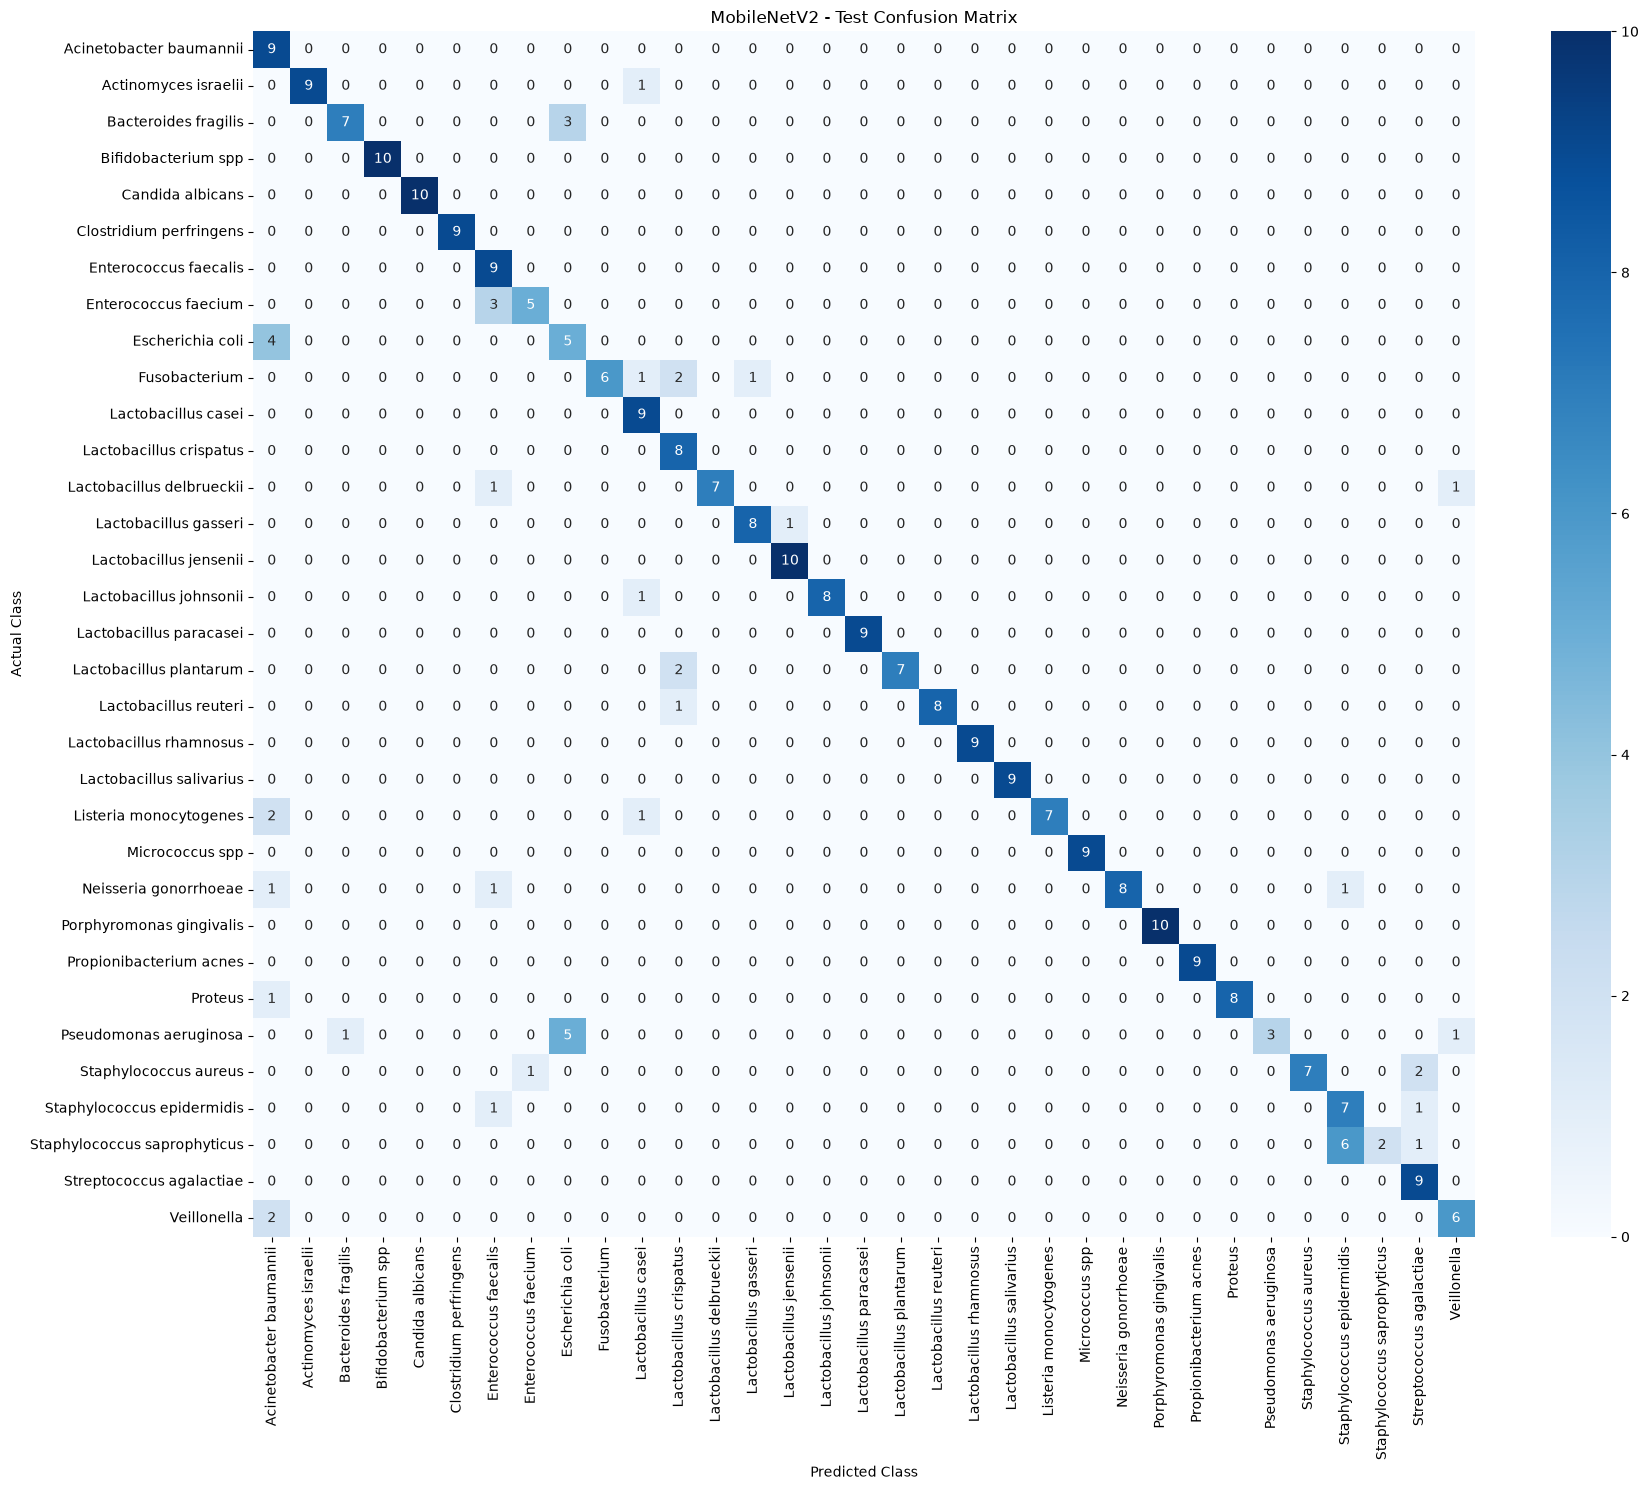

In [42]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Load the best fine-tuned checkpoint
final_model = tf.keras.models.load_model(
    "best_finetuned_mobilenetv2.keras"
)

# Save the selected model
final_model.save("final_microbial_classifier.keras")

# Evaluate on untouched test dataset
test_loss, test_acc = final_model.evaluate(
    test_ds,
    verbose=1
)

# Generate predictions
y_test = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob_test = final_model.predict(test_ds, verbose=0)
y_pred_test = np.argmax(y_prob_test, axis=1)

print("\nFINAL TEST RESULTS")
print("---------------------------")
print("Test Accuracy:", round(test_acc * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))
print("Predicted Classes:", len(np.unique(y_pred_test)))
print(
    "Average Confidence:",
    round(float(np.mean(np.max(y_prob_test, axis=1))) * 100, 2),
    "%"
)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_test,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_test,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(18, 15))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("MobileNetV2 - Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [45]:
import tensorflow as tf
import numpy as np

def predict_microorganism(image_path):

    # Load and preprocess image
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(image, (224, 224))
    image = tf.cast(image, tf.float32) / 255.0

    # Add batch dimension
    image = tf.expand_dims(image, axis=0)

    # Predict
    probabilities = final_model.predict(image, verbose=0)[0]

    # Get top 3 predictions
    top_indices = np.argsort(probabilities)[-3:][::-1]

    print("\nMICROBIAL CLASSIFICATION RESULTS")
    print("--------------------------------")

    for rank, index in enumerate(top_indices, start=1):
        print(
            f"{rank}. {class_names[index]}: "
            f"{probabilities[index] * 100:.2f}%"
        )

    return class_names[int(top_indices[0])]

In [46]:
result = predict_microorganism(
    r"C:\path\to\your\test_image.jpg"
)

print("\nFINAL PREDICTION:", result)

NotFoundError: {{function_node __wrapped__ReadFile_device_/job:localhost/replica:0/task:0/device:CPU:0}} NewRandomAccessFile failed to Create/Open: C:\path\to\your\test_image.jpg : The system cannot find the path specified.
; No such process [Op:ReadFile]

In [47]:
import random
from pathlib import Path

# Select a random image from the test dataset
sample = test_df.sample(1, random_state=42).iloc[0]

image_path = str(sample["filepath"])
actual_class = sample["label"]

print("IMAGE PATH:", image_path)
print("ACTUAL CLASS:", actual_class)

NameError: name 'test_df' is not defined

In [48]:
import numpy as np
import random
from pathlib import Path

# Select one batch from the test dataset
images, labels = next(iter(test_ds))

# Select a random image from this batch
index = random.randrange(len(images))

# Recover its original image path from test_df is unnecessary
sample_image = images[index]
actual_index = int(labels[index].numpy())
actual_class = class_names[actual_index]

print("ACTUAL CLASS:", actual_class)
print("IMAGE SHAPE:", sample_image.shape)

ACTUAL CLASS: Lactobacillus casei
IMAGE SHAPE: (224, 224, 3)


In [49]:
# Predict using the final trained model
probabilities = final_model.predict(
    tf.expand_dims(sample_image, axis=0),
    verbose=0
)[0]

top_indices = np.argsort(probabilities)[-3:][::-1]

print("\nMICROBIAL CLASSIFICATION RESULTS")
print("--------------------------------")

for rank, idx in enumerate(top_indices, start=1):
    print(
        f"{rank}. {class_names[idx]}: "
        f"{probabilities[idx] * 100:.2f}%"
    )

predicted_class = class_names[int(top_indices[0])]

print("\nACTUAL CLASS:", actual_class)
print("PREDICTED CLASS:", predicted_class)
print(
    "RESULT:",
    "CORRECT PREDICTION" if predicted_class == actual_class
    else "INCORRECT PREDICTION"
)


MICROBIAL CLASSIFICATION RESULTS
--------------------------------
1. Lactobacillus casei: 99.64%
2. Lactobacillus paracasei: 0.28%
3. Porphyromonas gingivalis: 0.05%

ACTUAL CLASS: Lactobacillus casei
PREDICTED CLASS: Lactobacillus casei
RESULT: CORRECT PREDICTION


In [50]:

import requests
import pandas as pd

# Search ChEMBL for E. coli antimicrobial MIC measurements
url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"

params = {
    "target_organism__icontains": "Escherichia coli",
    "standard_type": "MIC",
    "limit": 5,
    "offset": 0
}

response = requests.get(url, params=params, timeout=30)

print("HTTP STATUS:", response.status_code)

if response.status_code == 200:
    data = response.json()
    print("TOTAL MATCHING RECORDS:",
          data["page_meta"]["total_count"])

    df_preview = pd.DataFrame(data["activities"])

    print("\nAVAILABLE DATA:")
    print(df_preview.columns.tolist())

    print("\nFIRST 5 RECORDS:")
    display(df_preview.head())
else:
    print(response.text[:1000])


HTTP STATUS: 400
{"error_message": "'icontains' is not an allowed filter on the 'target_organism' field."}


In [51]:

import requests
import pandas as pd

url = "https://www.ebi.ac.uk/chembl/api/data/target/search.json"

params = {
    "q": "Escherichia coli",
    "limit": 20
}

response = requests.get(url, params=params, timeout=30)

print("HTTP STATUS:", response.status_code)

if response.status_code == 200:
    results = response.json()

    targets = pd.DataFrame(results.get("targets", []))

    if not targets.empty:
        columns = [
            col for col in [
                "target_chembl_id",
                "pref_name",
                "organism",
                "target_type"
            ] if col in targets.columns
        ]

        display(targets[columns])
    else:
        print("No matching targets found.")
else:
    print(response.text[:1000])


HTTP STATUS: 200


,target_chembl_id,pref_name,organism,target_type
0,CHEMBL354,Escherichia coli,Escherichia coli,ORGANISM
1,CHEMBL612336,Escherichia coli K-12,Escherichia coli K-12,ORGANISM
2,CHEMBL612611,Escherichia,Escherichia,ORGANISM
3,CHEMBL3233,Adenomatous polyposis coli protein,Homo sapiens,SINGLE PROTEIN
4,CHEMBL3301405,Campylobacter coli,Campylobacter coli,ORGANISM
5,CHEMBL6195229,Escherichia hermannii,Atlantibacter hermannii,ORGANISM
6,CHEMBL4296093,APC/Asef,Homo sapiens,PROTEIN COMPLEX
7,CHEMBL3885511,Adenomatous polyposis coli protein/Transcripti...,Homo sapiens,PROTEIN-PROTEIN INTERACTION
8,CHEMBL2364683,Bacterial urease,Bacteria,PROTEIN COMPLEX
9,CHEMBL3885646,Tryptophan synthase alpha /beta chains,Escherichia coli K-12,PROTEIN COMPLEX


In [52]:

import requests
import pandas as pd

url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"

params = {
    "target_chembl_id": "CHEMBL354",
    "standard_type": "MIC",
    "limit": 1000,
    "offset": 0
}

response = requests.get(url, params=params, timeout=30)

print("HTTP STATUS:", response.status_code)

if response.status_code == 200:
    result = response.json()

    activities = pd.DataFrame(result.get("activities", []))

    print("TOTAL MATCHING RECORDS:",
          result.get("page_meta", {}).get("total_count", 0))

    if not activities.empty:
        useful_columns = [
            "molecule_chembl_id",
            "standard_type",
            "standard_relation",
            "standard_value",
            "standard_units",
            "assay_chembl_id",
            "assay_description"
        ]

        useful_columns = [
            col for col in useful_columns
            if col in activities.columns
        ]

        display(activities[useful_columns].head(10))
    else:
        print("No MIC records found for this target.")
else:
    print(response.text[:1000])


HTTP STATUS: 200
TOTAL MATCHING RECORDS: 89438


,molecule_chembl_id,standard_type,standard_relation,standard_value,standard_units,assay_chembl_id,assay_description
0,CHEMBL1446,MIC,=,3.9,ug.mL-1,CHEMBL676856,Compound was tested in vitro for antibacterial...
1,CHEMBL78569,MIC,=,1.56,ug.mL-1,CHEMBL682927,Minimum inhibitory concentration against Esche...
2,CHEMBL309514,MIC,=,6.25,ug.mL-1,CHEMBL682927,Minimum inhibitory concentration against Esche...
3,CHEMBL96258,MIC,=,0.1,ug.mL-1,CHEMBL676848,Compound was tested for its minimal inhibitory...
4,CHEMBL96258,MIC,=,0.1,ug.mL-1,CHEMBL675580,Compound was tested for its minimal inhibitory...
5,CHEMBL275216,MIC,=,0.1,ug.mL-1,CHEMBL679318,Minimum inhibitory concentration against Esche...
6,CHEMBL15353,MIC,=,0.05,ug.mL-1,CHEMBL679318,Minimum inhibitory concentration against Esche...
7,CHEMBL15322,MIC,=,0.05,ug.mL-1,CHEMBL679318,Minimum inhibitory concentration against Esche...
8,CHEMBL279854,MIC,=,0.4,ug.mL-1,CHEMBL679318,Minimum inhibitory concentration against Esche...
9,CHEMBL2367615,MIC,=,8.0,ug.mL-1,CHEMBL673661,In vitro minimum inhibitory concentration agai...


In [53]:

print("DATASET SHAPE:", activities.shape)

print("\nMISSING VALUES:")
print(activities[
    ["molecule_chembl_id", "standard_value",
     "standard_units", "standard_relation",
     "assay_chembl_id"]
].isnull().sum())

print("\nMEASUREMENT UNITS:")
print(activities["standard_units"].value_counts().head(15))

print("\nMEASUREMENT RELATIONS:")
print(activities["standard_relation"].value_counts())

print("\nUNIQUE COMPOUNDS:",
      activities["molecule_chembl_id"].nunique())

print("\nUNIQUE ASSAYS:",
      activities["assay_chembl_id"].nunique())

print("\nMIC VALUE SUMMARY:")
print(pd.to_numeric(
    activities["standard_value"], errors="coerce"
).describe())


DATASET SHAPE: (1000, 47)

MISSING VALUES:
molecule_chembl_id    0
standard_value        1
standard_units        1
standard_relation     2
assay_chembl_id       0
dtype: int64

MEASUREMENT UNITS:
standard_units
ug.mL-1      871
ug cm**-2    118
nM             8
p.p.m.         2
Name: count, dtype: int64

MEASUREMENT RELATIONS:
standard_relation
=    837
>    139
<     22
Name: count, dtype: int64

UNIQUE COMPOUNDS: 595

UNIQUE ASSAYS: 98

MIC VALUE SUMMARY:
count    9.990000e+02
mean     2.585912e+05
std      3.781777e+06
min      3.000000e-03
25%      1.200000e-01
50%      8.000000e-01
75%      1.600000e+01
max      6.400000e+07
Name: standard_value, dtype: float64


In [54]:

# Keep only comparable, exact MIC measurements

clean_activities = activities[
    (activities["standard_units"] == "ug.mL-1") &
    (activities["standard_relation"] == "=")
].copy()

# Convert MIC values to numeric
clean_activities["standard_value"] = pd.to_numeric(
    clean_activities["standard_value"],
    errors="coerce"
)

# Remove missing and non-positive measurements
clean_activities = clean_activities.dropna(
    subset=["molecule_chembl_id", "standard_value"]
)

clean_activities = clean_activities[
    clean_activities["standard_value"] > 0
].copy()

# Calculate log10 MIC
import numpy as np

clean_activities["log_mic"] = np.log10(
    clean_activities["standard_value"]
)

print("ORIGINAL RECORDS:", len(activities))
print("CLEAN RECORDS:", len(clean_activities))

print("UNIQUE COMPOUNDS:",
      clean_activities["molecule_chembl_id"].nunique())

print("\nMIC DISTRIBUTION:")
print(clean_activities["standard_value"].describe())

print("\nLOG MIC DISTRIBUTION:")
print(clean_activities["log_mic"].describe())

print("\nCLEANED DATA PREVIEW:")
display(
    clean_activities[
        ["molecule_chembl_id", "standard_value", "standard_units", "log_mic"]
    ].head(10)
)


ORIGINAL RECORDS: 1000
CLEAN RECORDS: 751
UNIQUE COMPOUNDS: 511

MIC DISTRIBUTION:
count    7.510000e+02
mean     8.795259e+04
std      1.651743e+06
min      3.000000e-03
25%      1.000000e-01
50%      3.900000e-01
75%      3.130000e+00
max      3.200000e+07
Name: standard_value, dtype: float64

LOG MIC DISTRIBUTION:
count    751.000000
mean      -0.240009
std        1.181919
min       -2.522879
25%       -1.000000
50%       -0.408935
75%        0.495544
max        7.505150
Name: log_mic, dtype: float64

CLEANED DATA PREVIEW:


,molecule_chembl_id,standard_value,standard_units,log_mic
0,CHEMBL1446,3.90,ug.mL-1,0.591065
1,CHEMBL78569,1.56,ug.mL-1,0.193125
2,CHEMBL309514,6.25,ug.mL-1,0.795880
3,CHEMBL96258,0.10,ug.mL-1,-1.000000
4,CHEMBL96258,0.10,ug.mL-1,-1.000000
5,CHEMBL275216,0.10,ug.mL-1,-1.000000
6,CHEMBL15353,0.05,ug.mL-1,-1.301030
7,CHEMBL15322,0.05,ug.mL-1,-1.301030
8,CHEMBL279854,0.40,ug.mL-1,-0.397940
9,CHEMBL2367615,8.00,ug.mL-1,0.903090


In [57]:

import requests
import pandas as pd
import time

# Get unique compound IDs from our cleaned dataset
compound_ids = sorted(
    clean_activities["molecule_chembl_id"].dropna().unique()
)

print("COMPOUNDS TO RETRIEVE:", len(compound_ids))

base_url = "https://www.ebi.ac.uk/chembl/api/data/molecule.json"

molecule_records = []

# Retrieve compounds in batches of 100
for start in range(0, len(compound_ids), 100):

    batch_ids = compound_ids[start:start + 100]

    params = {
        "molecule_chembl_id__in": ",".join(batch_ids),
        "limit": 100,
        "offset": 0
    }

    response = requests.get(
        base_url,
        params=params,
        timeout=60
    )

    response.raise_for_status()

    molecules = response.json().get("molecules", [])

    for molecule in molecules:

        properties = molecule.get("molecule_properties") or {}
        structures = molecule.get("molecule_structures") or {}

        molecule_records.append({
            "molecule_chembl_id": molecule.get("molecule_chembl_id"),
            "compound_name": molecule.get("pref_name"),
            "molecular_weight": properties.get("full_mwt"),
            "alogp": properties.get("alogp"),
            "hba": properties.get("hba"),
            "hbd": properties.get("hbd"),
            "psa": properties.get("psa"),
            "rotatable_bonds": properties.get("rtb"),
            "canonical_smiles": structures.get("canonical_smiles")
        })

    print(
        f"Retrieved {min(start + 100, len(compound_ids))}"
        f"/{len(compound_ids)} compounds"
    )

    time.sleep(0.2)

# Create descriptor DataFrame
descriptors_df = pd.DataFrame(molecule_records)

print("\nDESCRIPTOR DATASET SHAPE:", descriptors_df.shape)
print("UNIQUE COMPOUNDS RETRIEVED:",
      descriptors_df["molecule_chembl_id"].nunique())

display(descriptors_df.head(10))


COMPOUNDS TO RETRIEVE: 511
Retrieved 100/511 compounds
Retrieved 200/511 compounds
Retrieved 300/511 compounds
Retrieved 400/511 compounds
Retrieved 500/511 compounds
Retrieved 511/511 compounds

DESCRIPTOR DATASET SHAPE: (511, 9)
UNIQUE COMPOUNDS RETRIEVED: 511


,molecule_chembl_id,compound_name,molecular_weight,alogp,hba,hbd,psa,rotatable_bonds,canonical_smiles
0,CHEMBL13779,CARBADOX,262.23,-0.20,5.0,1.0,104.57,2.0,COC(=O)N/N=C/c1c[n+]([O-])c2ccccc2[n+]1[O-]
1,CHEMBL15112,NaN,417.39,2.86,5.0,1.0,65.78,3.0,CN1CCN(c2cc3c(cc2F)c(=O)c(C(=O)O)cn3-c2ccc(F)c...
2,CHEMBL14894,NaN,347.39,1.90,5.0,2.0,74.57,5.0,CCn1cc(C(=O)O)c(=O)c2cc(F)c(N3CCC(CNC)C3)cc21
3,CHEMBL14851,NaN,431.41,3.15,5.0,2.0,74.57,5.0,CNCC1CCN(c2cc3c(cc2F)c(=O)c(C(=O)O)cn3-c2ccc(F...
4,CHEMBL14866,NaN,373.43,2.75,5.0,2.0,74.57,3.0,CC1CN(c2cc3c(cc2F)c(=O)c(C(=O)O)cn3C2CCC2)CC(C)N1
5,CHEMBL14919,NaN,363.36,2.10,5.0,2.0,88.56,4.0,NCC1CCN(c2c(F)cc3c(=O)c(C(=O)O)cn(C4CC4)c3c2F)C1
6,CHEMBL15028,NaN,389.43,2.36,6.0,2.0,97.79,5.0,COc1c(N2CCC(CN)CC2)c(F)cc2c(=O)c(C(=O)O)cn(C3C...
7,CHEMBL15071,NaN,390.42,1.69,7.0,3.0,123.81,4.0,COc1c(N2CCCC(N)C2)c(F)c(N)c2c(=O)c(C(=O)O)cn(C...
8,CHEMBL14937,NaN,361.37,1.59,6.0,2.0,83.80,4.0,COc1c(N2CCNCC2)c(F)cc2c(=O)c(C(=O)O)cn(C3CC3)c12
9,CHEMBL14979,NaN,459.47,3.88,5.0,1.0,65.78,5.0,CC(C)CN1CCN(c2cc3c(cc2F)c(=O)c(C(=O)O)cn3-c2cc...


In [58]:

# Select molecular descriptors for machine learning
descriptor_columns = [
    "molecular_weight",
    "alogp",
    "hba",
    "hbd",
    "psa",
    "rotatable_bonds"
]

# Aggregate repeated MIC measurements for each compound
mic_data = (
    clean_activities
    .groupby("molecule_chembl_id")
    .agg(
        log_mic=("log_mic", "median"),
        mic_measurements=("log_mic", "count")
    )
    .reset_index()
)

# Merge MIC data with molecular descriptors
drug_dataset = mic_data.merge(
    descriptors_df,
    on="molecule_chembl_id",
    how="inner"
)

# Convert descriptor columns to numeric
for column in descriptor_columns:
    drug_dataset[column] = pd.to_numeric(
        drug_dataset[column], errors="coerce"
    )

# Remove rows with missing model features or target
drug_dataset = drug_dataset.dropna(
    subset=descriptor_columns + ["log_mic"]
).copy()

print("FINAL DRUG DISCOVERY DATASET:", drug_dataset.shape)

print("\nUNIQUE COMPOUNDS:",
      drug_dataset["molecule_chembl_id"].nunique())

print("\nMISSING VALUES:")
print(drug_dataset[descriptor_columns + ["log_mic"]].isnull().sum())

print("\nMIC MEASUREMENT COUNTS:")
print(drug_dataset["mic_measurements"].value_counts().head())

print("\nFINAL DATASET PREVIEW:")
display(
    drug_dataset[
        ["molecule_chembl_id"] +
        descriptor_columns +
        ["log_mic", "mic_measurements"]
    ].head(10)
)


FINAL DRUG DISCOVERY DATASET: (473, 11)

UNIQUE COMPOUNDS: 473

MISSING VALUES:
molecular_weight    0
alogp               0
hba                 0
hbd                 0
psa                 0
rotatable_bonds     0
log_mic             0
dtype: int64

MIC MEASUREMENT COUNTS:
mic_measurements
1    355
2     97
4      7
3      5
6      4
Name: count, dtype: int64

FINAL DATASET PREVIEW:


,molecule_chembl_id,molecular_weight,alogp,hba,hbd,psa,rotatable_bonds,log_mic,mic_measurements
0,CHEMBL107929,423.39,-1.16,10.0,3.0,174.24,7.0,-1.522879,1
1,CHEMBL1082,365.41,0.02,6.0,4.0,132.96,4.0,0.204120,1
2,CHEMBL108293,472.51,-1.25,11.0,3.0,184.59,8.0,-0.903090,1
4,CHEMBL109082,504.52,-0.91,11.0,3.0,184.59,10.0,-0.903090,1
5,CHEMBL109281,444.45,-2.03,11.0,3.0,184.59,6.0,-1.221849,4
6,CHEMBL109583,520.98,-0.64,11.0,3.0,184.59,10.0,-0.301030,1
7,CHEMBL109746,537.37,-1.26,11.0,3.0,184.59,8.0,-0.903090,1
8,CHEMBL109943,433.45,-0.33,10.0,3.0,174.24,8.0,0.000000,1
9,CHEMBL109959,348.34,-1.31,8.0,3.0,152.65,4.0,1.204120,1
10,CHEMBL110643,535.00,-0.25,11.0,3.0,184.59,11.0,-0.301030,1


In [59]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Define input features and target
features = [
    "molecular_weight",
    "alogp",
    "hba",
    "hbd",
    "psa",
    "rotatable_bonds"
]

X = drug_dataset[features]
y = drug_dataset["log_mic"]

# 2. Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("TRAINING SAMPLES:", len(X_train))
print("TESTING SAMPLES:", len(X_test))

# 3. Create Random Forest model
drug_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# 4. Train model
drug_model.fit(X_train, y_train)

# 5. Predict MIC values
y_pred = drug_model.predict(X_test)

# 6. Evaluate model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nDRUG DISCOVERY MODEL RESULTS")
print("--------------------------------")
print("R2 SCORE:", round(r2, 4))
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

# 7. Compare against a simple baseline
baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("\nBASELINE MODEL")
print("--------------------------------")
print("Baseline MAE:",
      round(mean_absolute_error(y_test, baseline_pred), 4))

# 8. Feature importance
importance = pd.DataFrame({
    "Feature": features,
    "Importance": drug_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nFEATURE IMPORTANCE")
display(importance)


TRAINING SAMPLES: 378
TESTING SAMPLES: 95

DRUG DISCOVERY MODEL RESULTS
--------------------------------
R2 SCORE: 0.4935
MAE: 0.5149
RMSE: 0.877

BASELINE MODEL
--------------------------------
Baseline MAE: 0.791

FEATURE IMPORTANCE


,Feature,Importance
0,molecular_weight,0.391571
1,alogp,0.216594
4,psa,0.163940
5,rotatable_bonds,0.096555
2,hba,0.071654
3,hbd,0.059685


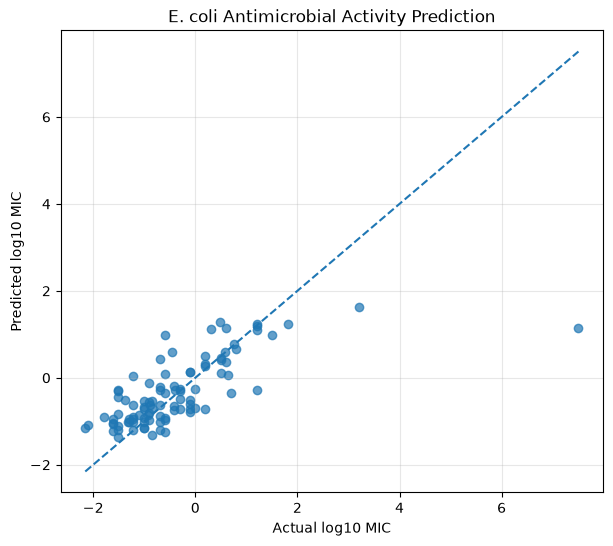

In [60]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Ideal prediction reference line
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual log10 MIC")
plt.ylabel("Predicted log10 MIC")
plt.title("E. coli Antimicrobial Activity Prediction")
plt.grid(alpha=0.3)

plt.show()


In [61]:
import joblib
import json

# Save trained model
joblib.dump(drug_model, "antimicrobial_activity_model.pkl")

# Save feature names
with open("drug_model_features.json", "w") as file:
    json.dump(features, file, indent=4)

print("MODEL SAVED SUCCESSFULLY")
print("File: antimicrobial_activity_model.pkl")
print("File: drug_model_features.json")

MODEL SAVED SUCCESSFULLY
File: antimicrobial_activity_model.pkl
File: drug_model_features.json


In [62]:
import numpy as np
import pandas as pd

# Predict antimicrobial activity for test compounds
screening_results = drug_dataset.loc[X_test.index].copy()

screening_results["predicted_log_mic"] = drug_model.predict(X_test)

# Convert log MIC back to MIC in µg/mL
screening_results["predicted_mic_ug_ml"] = (
    10 ** screening_results["predicted_log_mic"]
)

screening_results["actual_mic_ug_ml"] = (
    10 ** screening_results["log_mic"]
)

# Rank compounds by lowest predicted MIC
screening_results = screening_results.sort_values(
    "predicted_mic_ug_ml",
    ascending=True
)

# Display top 10 candidates
top_candidates = screening_results[
    [
        "molecule_chembl_id",
        "predicted_mic_ug_ml",
        "actual_mic_ug_ml",
        "molecular_weight",
        "alogp"
    ]
].head(10)

print("TOP 10 PREDICTED ANTIMICROBIAL CANDIDATES")
display(top_candidates)

TOP 10 PREDICTED ANTIMICROBIAL CANDIDATES


,molecule_chembl_id,predicted_mic_ug_ml,actual_mic_ug_ml,molecular_weight,alogp
440,CHEMBL47891,0.042592,0.030000,342.40,1.41
77,CHEMBL146339,0.048889,0.141421,376.39,1.13
56,CHEMBL136013,0.056152,0.250000,346.36,1.49
504,CHEMBL94037,0.060636,0.025000,405.48,1.31
453,CHEMBL6256,0.062822,0.200000,380.40,1.59
407,CHEMBL424288,0.064090,0.030000,370.45,2.19
431,CHEMBL45887,0.064675,0.060000,340.35,3.54
34,CHEMBL131685,0.070991,0.007000,365.79,2.36
94,CHEMBL15071,0.071573,0.100000,390.42,1.69
78,CHEMBL14714,0.071573,0.100000,390.42,1.69


In [63]:
from scipy.stats import spearmanr

# Compare predicted and actual MIC rankings
spearman_corr, p_value = spearmanr(
    screening_results["predicted_log_mic"],
    screening_results["log_mic"]
)

# Top 10 according to actual experimental MIC
actual_top10 = set(
    screening_results.nsmallest(10, "actual_mic_ug_ml")[
        "molecule_chembl_id"
    ]
)

# Top 10 according to predicted MIC
predicted_top10 = set(
    screening_results.nsmallest(10, "predicted_mic_ug_ml")[
        "molecule_chembl_id"
    ]
)

common_compounds = actual_top10.intersection(predicted_top10)

print("RANKING VALIDATION")
print("--------------------------------")
print("Spearman correlation:", round(spearman_corr, 4))
print("P-value:", round(p_value, 6))
print("Top 10 overlap:", len(common_compounds), "/ 10")
print("Common compounds:", sorted(common_compounds))

RANKING VALIDATION
--------------------------------
Spearman correlation: 0.7412
P-value: 0.0
Top 10 overlap: 4 / 10
Common compounds: ['CHEMBL131685', 'CHEMBL424288', 'CHEMBL47891', 'CHEMBL94037']


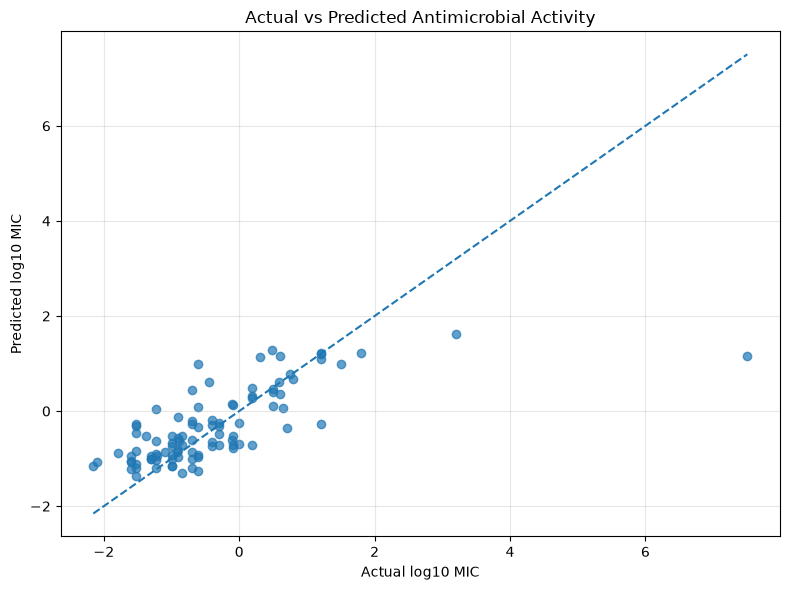

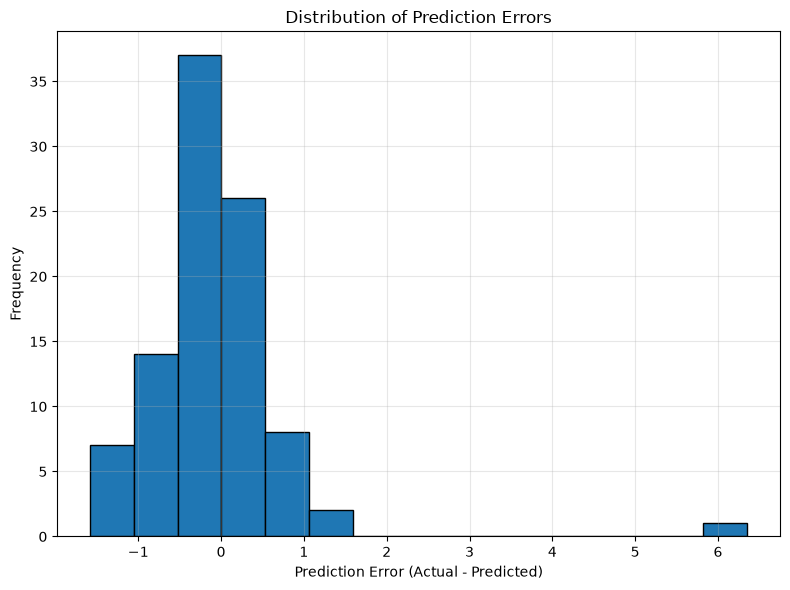

BOTH GRAPHS SAVED SUCCESSFULLY


In [64]:
import matplotlib.pyplot as plt
import numpy as np

# Graph 1: Actual vs Predicted
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual log10 MIC")
plt.ylabel("Predicted log10 MIC")
plt.title("Actual vs Predicted Antimicrobial Activity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("actual_vs_predicted_mic.png", dpi=300)
plt.show()


# Graph 2: Prediction error distribution
errors = y_test - y_pred

plt.figure(figsize=(8, 6))
plt.hist(errors, bins=15, edgecolor="black")

plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("prediction_error_distribution.png", dpi=300)
plt.show()

print("BOTH GRAPHS SAVED SUCCESSFULLY")